# Project Deliverable 1: Data Collection, Cleaning, and Exploration
### Advanced Data Mining for Data-Driven Insights and Predictive Modeling

**Group AA:** Anushka Nanaware, Anusha Pittala

**Course:** MSCS-634-M50 - Advanced Big Data and Data Mining

**Assignment:** Residency Day 1 - Project Deliverable 1

## 1. Dataset Selection and Description

**Dataset:** Telco Customer Churn (a sample customer dataset from IBM, widely used for churn analysis)

**What it contains:** 7,043 customers of a telecom company and 21 attributes. Each row is one customer. The attributes include:
- **Customer details:** gender, senior citizen, partner, dependents
- **Account details:** tenure (months with the company), contract type, paperless billing, payment method
- **Services:** phone service, multiple lines, internet service, online security, online backup, device protection, tech support, streaming TV, streaming movies
- **Charges:** monthly charges and total charges
- **Target:** Churn (whether the customer left the company)

**Why this dataset is appropriate:**
- It meets the requirements: 7,043 records (more than 500) and 21 attributes (more than 8 to 10).
- It is real-world customer behavior data, with a clear business problem: finding which customers are likely to leave and why.
- It has a mix of numeric attributes (tenure, monthly charges, total charges) and categorical attributes, so it works for every part of this project: regression (predicting charges), classification (predicting churn), clustering (customer segments), and association rule mining (which services are bought together).
- It needs real cleaning, including text numbers, blank values, and repeated category labels, which gives me meaningful preprocessing to practice.
- It also contains personal attributes such as gender and senior citizen status, which lets me think about fairness and ethics later in the project.

**Source:** IBM sample data repository on GitHub (also available on Kaggle as "Telco Customer Churn").

In [21]:
# Import the libraries we will use throughout this project
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Telco Customer Churn dataset directly from the IBM GitHub repository
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

# How many rows (customers) and columns (attributes) do we have?
print("Shape (rows, columns):", df.shape)

Shape (rows, columns): (7043, 21)


In [22]:
# Show the first 5 rows to see what the data looks like
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [23]:
# info() shows each column's name, data type, and how many values are not empty
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [24]:
# describe() gives count, mean, spread, min, and max for numeric columns
df.describe().round(2)

,SeniorCitizen,tenure,MonthlyCharges
count,7043.00,7043.00,7043.00
mean,0.16,32.37,64.76
std,0.37,24.56,30.09
min,0.00,0.00,18.25
25%,0.00,9.00,35.50
50%,0.00,29.00,70.35
75%,0.00,55.00,89.85
max,1.00,72.00,118.75


In [25]:
# For each text column, show the different values it contains
# (skip customerID and TotalCharges, which have too many unique values)
text_cols = df.select_dtypes(include=["object", "string"]).columns.drop(["customerID", "TotalCharges"])

for col in text_cols:
    print(col, "->", df[col].unique().tolist())

gender -> ['Female', 'Male']
Partner -> ['Yes', 'No']
Dependents -> ['No', 'Yes']
PhoneService -> ['No', 'Yes']
MultipleLines -> ['No phone service', 'No', 'Yes']
InternetService -> ['DSL', 'Fiber optic', 'No']
OnlineSecurity -> ['No', 'Yes', 'No internet service']
OnlineBackup -> ['Yes', 'No', 'No internet service']
DeviceProtection -> ['No', 'Yes', 'No internet service']
TechSupport -> ['No', 'Yes', 'No internet service']
StreamingTV -> ['No', 'Yes', 'No internet service']
StreamingMovies -> ['No', 'Yes', 'No internet service']
Contract -> ['Month-to-month', 'One year', 'Two year']
PaperlessBilling -> ['Yes', 'No']
PaymentMethod -> ['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']
Churn -> ['No', 'Yes']


### Step 2 Observations: Initial Inspection

- The dataset has **7,043 rows** (one per customer) and **21 columns**: 18 text columns, 2 integer columns (`SeniorCitizen`, `tenure`), and 1 decimal column (`MonthlyCharges`).
- `info()` shows no missing values at first glance, but `TotalCharges` is stored as **text** instead of a number. This is a data type problem that I need to fix before any analysis.
- `tenure` ranges from 0 to 72 months, with an average of about 32 months. A tenure of 0 means a customer who just joined and needs a closer look.
- MonthlyCharges ranges from about \$18 to \$119, with an average of about \$65.
- `SeniorCitizen` is stored as 0/1, while the other yes/no columns use "Yes"/"No". I may need to make these consistent.
- Several columns contain "No internet service" or "No phone service", which are really the same as "No" for the service in question. I will need to decide how to handle these repeated labels in the cleaning step.
- `Churn` has two values (Yes and No), so it is a good target for classification later.

## Step 3: Data Cleaning
In this step I check the data for missing values, duplicates, inconsistent labels and noisy values. I work on a copy called df_clean, so the original df stays untouched.

In [26]:
# The usual isnull() check can miss values that are stored as blank text.
print("Missing values (standard check):", df.isnull().sum().sum())

# TotalCharges looked like text earlier, so I look for blank strings
blank_mask = df["TotalCharges"].astype(str).str.strip() == ""
print("Blank TotalCharges entries:", blank_mask.sum())

# Look at those rows to understand why they are blank
df.loc[blank_mask, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Missing values (standard check): 0
Blank TotalCharges entries: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [27]:
# Make a copy so the raw data stays safe
df_clean = df.copy()

# Convert TotalCharges from text to numbers. Blank spaces become NaN.
df_clean["TotalCharges"] = pd.to_numeric(df_clean["TotalCharges"], errors="coerce")
print("Missing TotalCharges after conversion:", df_clean["TotalCharges"].isnull().sum())

# All 11 rows have tenure = 0, so these customers have not been billed yet.
# Their real total is 0, so I fill with 0 instead of deleting the rows.
df_clean["TotalCharges"] = df_clean["TotalCharges"].fillna(0)

print("Missing TotalCharges now:", df_clean["TotalCharges"].isnull().sum())
print("TotalCharges data type:", df_clean["TotalCharges"].dtype)

Missing TotalCharges after conversion: 11
Missing TotalCharges now: 0
TotalCharges data type: float64


In [28]:
# Check for duplicate rows and duplicate customer IDs
print("Duplicate rows:", df_clean.duplicated().sum())
print("Duplicate customer IDs:", df_clean["customerID"].duplicated().sum())

# Check every text column for extra spaces at the start or end
text_cols = df_clean.select_dtypes(include=["object", "string"]).columns
space_issues = sum((df_clean[col] != df_clean[col].str.strip()).sum() for col in text_cols)
print("Text values with extra spaces:", space_issues)

Duplicate rows: 0
Duplicate customer IDs: 0
Text values with extra spaces: 0


In [29]:
# Check: do the extra labels match exactly with the internet/phone columns?
print("Rows saying 'No internet service' in OnlineSecurity:", (df_clean["OnlineSecurity"] == "No internet service").sum())
print("Customers with InternetService = No:", (df_clean["InternetService"] == "No").sum())
print("Rows saying 'No phone service' in MultipleLines:", (df_clean["MultipleLines"] == "No phone service").sum())
print("Customers with PhoneService = No:", (df_clean["PhoneService"] == "No").sum())

# The counts match, so these labels repeat information we already have.
# I change them to "No" so each service column has only Yes / No.
service_cols = ["MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
                "TechSupport", "StreamingTV", "StreamingMovies"]
for col in service_cols:
    df_clean[col] = df_clean[col].replace({"No internet service": "No", "No phone service": "No"})

# SeniorCitizen is 0/1 while every other column uses Yes/No, so I make it match
df_clean["SeniorCitizen"] = df_clean["SeniorCitizen"].map({0: "No", 1: "Yes"})

# Confirm the labels are now consistent
for col in service_cols + ["SeniorCitizen"]:
    print(col, "->", sorted(df_clean[col].unique().tolist()))

Rows saying 'No internet service' in OnlineSecurity: 1526
Customers with InternetService = No: 1526
Rows saying 'No phone service' in MultipleLines: 682
Customers with PhoneService = No: 682
MultipleLines -> ['No', 'Yes']
OnlineSecurity -> ['No', 'Yes']
OnlineBackup -> ['No', 'Yes']
DeviceProtection -> ['No', 'Yes']
TechSupport -> ['No', 'Yes']
StreamingTV -> ['No', 'Yes']
StreamingMovies -> ['No', 'Yes']
SeniorCitizen -> ['No', 'Yes']


In [30]:
# Noise check: TotalCharges should be close to tenure x MonthlyCharges
expected_total = df_clean["tenure"] * df_clean["MonthlyCharges"]
ratio = df_clean["TotalCharges"] / expected_total.replace(0, np.nan)   # skip tenure = 0 rows
print(ratio.describe().round(3))
print("Customers where TotalCharges differs from tenure x MonthlyCharges by more than 20%:", ((ratio < 0.8) | (ratio > 1.2)).sum())
print("Customers where it differs by more than 50%:", ((ratio < 0.5) | (ratio > 1.5)).sum())

# Outlier check with the IQR rule (values beyond 1.5 x IQR from the quartiles)
for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
    q1, q3 = df_clean[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df_clean[col] < low) | (df_clean[col] > high)).sum()
    print(f"{col}: acceptable range {low:.1f} to {high:.1f}, outliers found = {n_out}")

count    7032.000
mean        1.000
std         0.051
min         0.689
25%         0.980
50%         1.000
75%         1.020
max         1.573
dtype: float64
Customers where TotalCharges differs from tenure x MonthlyCharges by more than 20%: 59
Customers where it differs by more than 50%: 2
tenure: acceptable range -60.0 to 124.0, outliers found = 0
MonthlyCharges: acceptable range -46.0 to 171.4, outliers found = 0
TotalCharges: acceptable range -4683.5 to 8868.7, outliers found = 0


In [31]:
# Before and after comparison
print("Original shape:", df.shape)
print("Cleaned shape :", df_clean.shape)
print("Total missing values:", df_clean.isnull().sum().sum())
print(df_clean.dtypes.value_counts())

df_clean.head(3)

Original shape: (7043, 21)
Cleaned shape : (7043, 21)
Total missing values: 0
object     18
float64     2
int64       1
Name: count, dtype: int64


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,No,Yes,No,1,No,No,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


### Cleaning Summary

**1. Missing values.** The standard isnull() check found nothing, but TotalCharges had 11 blank text values. All 11 customers have tenure = 0 and have not churned, so they are brand-new customers who were not billed yet. I converted the column to numbers and filled these with 0. I kept the rows because deleting them would lose real customers for no good reason.

**2. Duplicates.** There were no duplicate rows and no duplicate customer IDs, so nothing was removed.

**3. Inconsistent data.** Six service columns used the label "No internet service" and MultipleLines used "No phone service". These match exactly the customers with no internet or phone, so they repeat information that is already in InternetService and PhoneService. I changed them to "No". I also changed SeniorCitizen from 0/1 to No/Yes so it matches the other columns.

**4. Noisy data.** TotalCharges should be roughly tenure x MonthlyCharges. The average ratio is 1.0, and only 59 customers differ by more than 20% (just 2 by more than 50%). This is normal noise from price changes over time, not data entry errors, so I kept these rows.

**5. Outliers.** The IQR rule found no outliers in tenure, MonthlyCharges or TotalCharges. The data looks clean and the spread of values is realistic.

## Step 4: Exploratory Data Analysis (EDA)
Here I use Seaborn and Matplotlib to look at (1) the target variable Churn, (2) the distributions of the numeric columns, (3) outliers, and (4) how the features relate to churn.

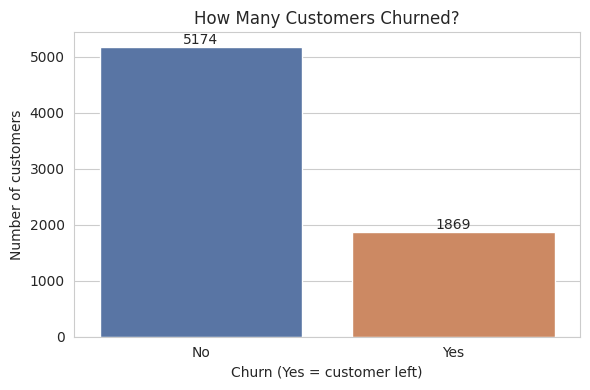

Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64


In [32]:
# Set a clean look for all charts
sns.set_style("whitegrid")

# Count how many customers churned and how many stayed
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df_clean, x="Churn", hue="Churn",
              palette=["#4C72B0", "#DD8452"], legend=False, ax=ax)

# Write the count on top of each bar
for bar in ax.patches:
    ax.annotate(f"{int(bar.get_height())}",
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom")

ax.set_title("How Many Customers Churned?")
ax.set_xlabel("Churn (Yes = customer left)")
ax.set_ylabel("Number of customers")
plt.tight_layout()
plt.show()

# Same thing as percentages
print(df_clean["Churn"].value_counts(normalize=True).mul(100).round(1))

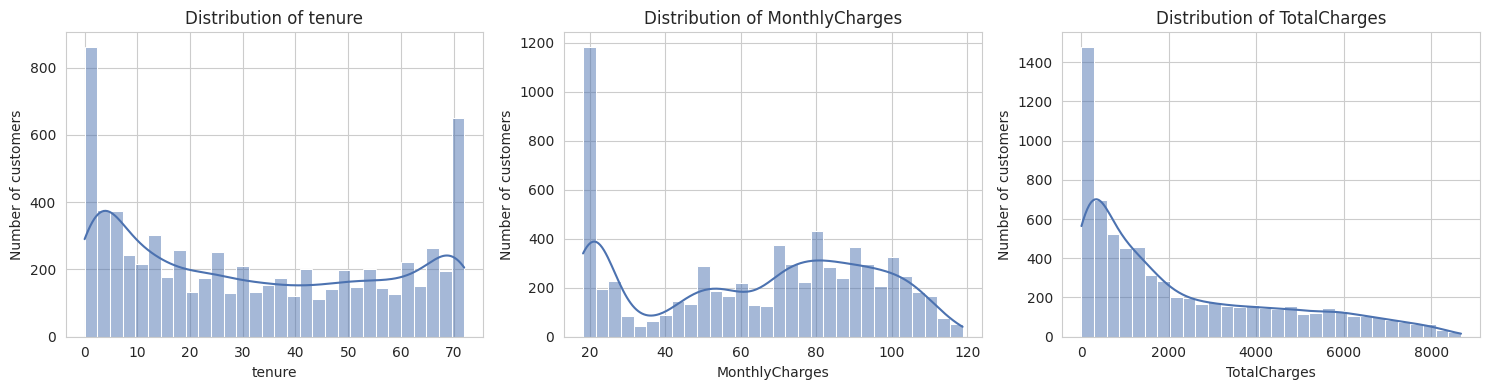

Skewness:
tenure            0.24
MonthlyCharges   -0.22
TotalCharges      0.96
dtype: float64


In [33]:
# Histograms show the shape of each numeric column
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(df_clean[col], bins=30, kde=True, ax=ax, color="#4C72B0")
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of customers")
plt.tight_layout()
plt.show()

# Skewness: 0 = symmetric, positive = long tail to the right
print("Skewness:")
print(df_clean[num_cols].skew().round(2))

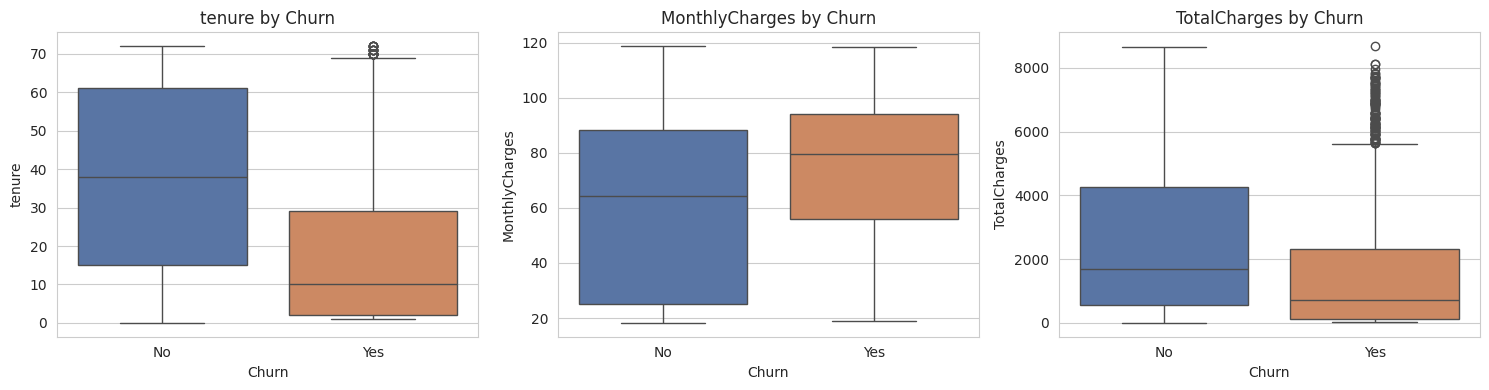

       tenure  MonthlyCharges  TotalCharges
Churn                                      
No       38.0            64.4        1679.5
Yes      10.0            79.6         703.6


In [34]:
# Boxplots show the spread and any outliers (dots outside the whiskers).
# Splitting by Churn also shows how churners differ from loyal customers.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df_clean, x="Churn", y=col, hue="Churn",
                palette=["#4C72B0", "#DD8452"], legend=False, ax=ax)
    ax.set_title(f"{col} by Churn")
plt.tight_layout()
plt.show()

# Median values for each group
print(df_clean.groupby("Churn")[num_cols].median().round(1))

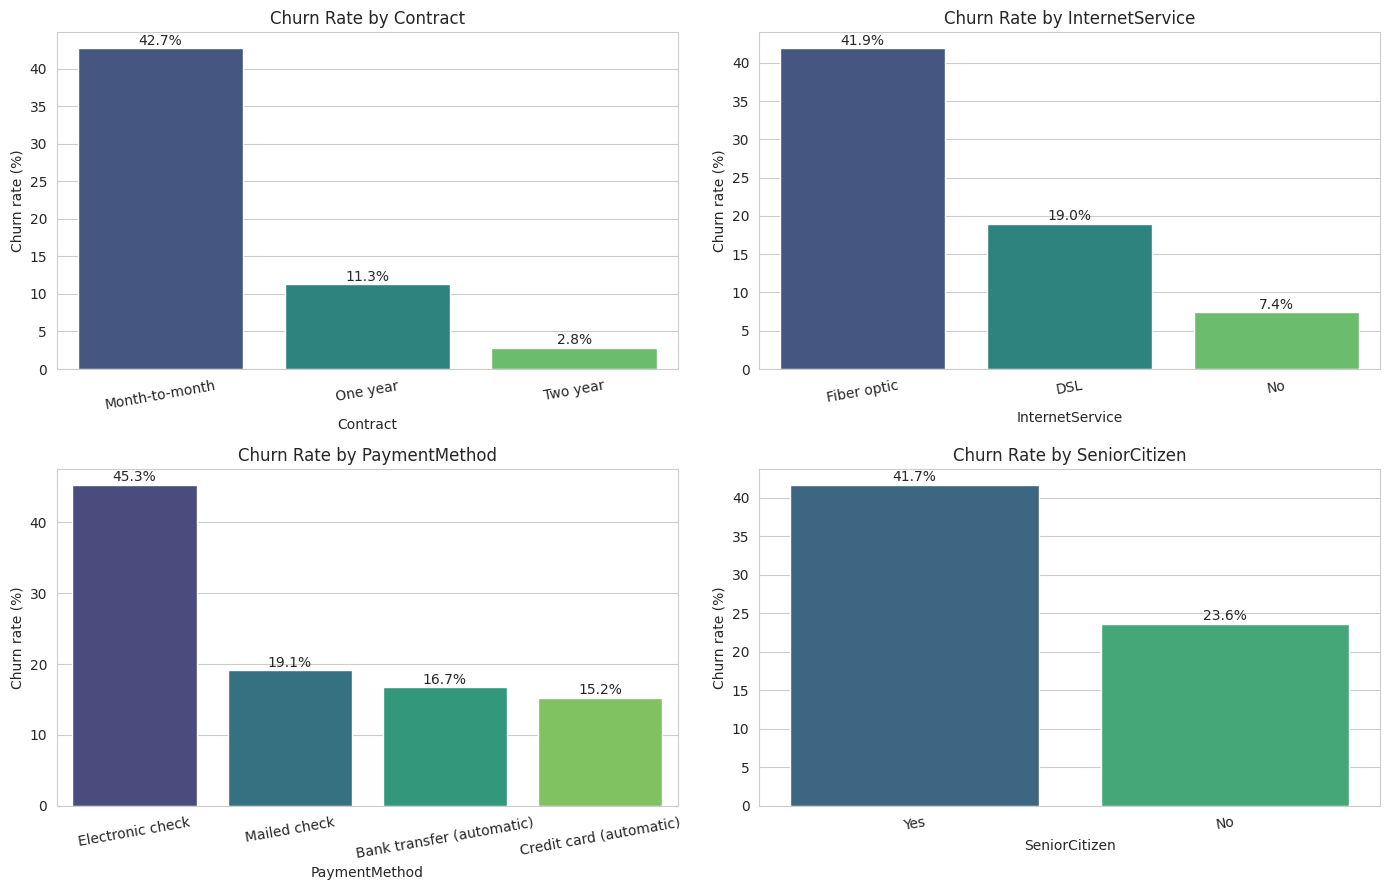

In [35]:
# For each category, calculate the % of customers who churned
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.flatten(), ["Contract", "InternetService", "PaymentMethod", "SeniorCitizen"]):
    rate = df_clean.groupby(col)["Churn"].apply(lambda s: (s == "Yes").mean() * 100)
    rate = rate.sort_values(ascending=False)
    sns.barplot(x=rate.index, y=rate.values, hue=rate.index,
                palette="viridis", legend=False, ax=ax)
    # Write the percentage on top of each bar
    for i, v in enumerate(rate.values):
        ax.text(i, v + 0.5, f"{v:.1f}%", ha="center")
    ax.set_title(f"Churn Rate by {col}")
    ax.set_ylabel("Churn rate (%)")
    ax.tick_params(axis="x", rotation=10)
plt.tight_layout()
plt.show()

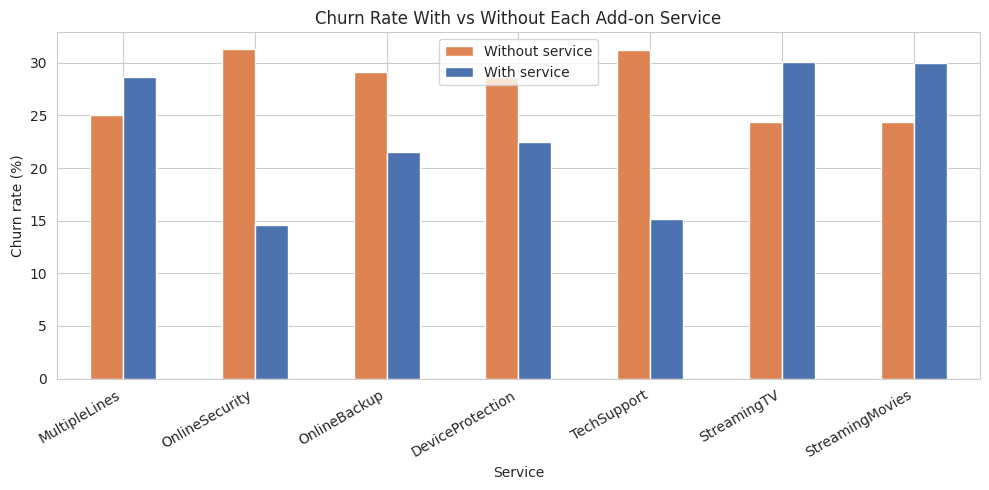

                  Without service  With service
Service                                        
MultipleLines                25.0          28.6
OnlineSecurity               31.3          14.6
OnlineBackup                 29.2          21.5
DeviceProtection             28.7          22.5
TechSupport                  31.2          15.2
StreamingTV                  24.3          30.1
StreamingMovies              24.4          29.9


In [36]:
# Compare churn rate for customers who have each add-on service vs those who do not
service_cols = ["MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
                "TechSupport", "StreamingTV", "StreamingMovies"]

rows = []
for col in service_cols:
    rate = df_clean.groupby(col)["Churn"].apply(lambda s: (s == "Yes").mean() * 100)
    rows.append({"Service": col, "Without service": rate["No"], "With service": rate["Yes"]})
service_rates = pd.DataFrame(rows).set_index("Service")

service_rates.plot(kind="bar", figsize=(10, 5), color=["#DD8452", "#4C72B0"])
plt.title("Churn Rate With vs Without Each Add-on Service")
plt.ylabel("Churn rate (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

print(service_rates.round(1))

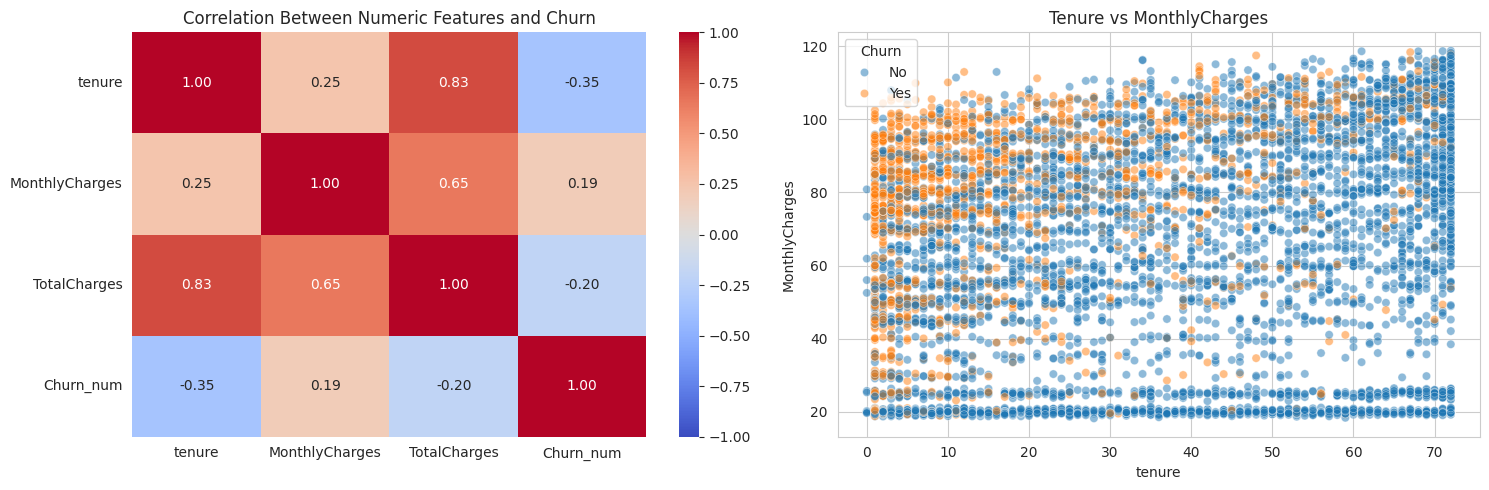

In [37]:
# Turn Churn into 0/1 so it can be included in the correlation
df_corr = df_clean.copy()
df_corr["Churn_num"] = (df_corr["Churn"] == "Yes").astype(int)
corr = df_corr[["tenure", "MonthlyCharges", "TotalCharges", "Churn_num"]].corr()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: correlation heatmap
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Correlation Between Numeric Features and Churn")

# Right: tenure vs MonthlyCharges, coloured by churn
sns.scatterplot(data=df_clean, x="tenure", y="MonthlyCharges", hue="Churn", alpha=0.5, ax=axes[1])
axes[1].set_title("Tenure vs MonthlyCharges")

plt.tight_layout()
plt.show()

### EDA Observations

**Target variable.** About 73.5% of customers stayed and 26.5% churned. The classes are imbalanced, so accuracy alone will be misleading later and I will also use precision, recall and F1.

**Distributions.** tenure has two peaks: many brand-new customers and many long-term customers. MonthlyCharges has a big group near the lowest price (customers with phone only) and then a wide spread. TotalCharges is skewed to the right (skewness 0.96) because it grows with tenure, so a log transform may help later.

**Outliers.** The IQR check on the full dataset found no outliers. In the boxplots split by Churn, a few dots appear only inside the churner group: 23 churners with tenure of 70 to 72 months and 109 with high TotalCharges. They look unusual only because most churners leave early. They are real long-term customers, not errors, so I kept them. Customers who churned have a much lower median tenure (10 vs 38 months) and a higher median MonthlyCharges (79.6 vs 64.4).

**Churn by category.** Month-to-month contracts churn at 42.7%, compared with 11.3% for one-year and 2.8% for two-year contracts. Fiber optic customers churn at 41.9%, compared with 19.0% for DSL. Electronic check users churn at 45.3%, far above the other payment methods (15% to 19%). Senior citizens churn at 41.7% vs 23.6% for others. Gender makes almost no difference (26.9% vs 26.2%).

**Add-on services.** Customers with OnlineSecurity (14.6%) or TechSupport (15.2%) churn about half as much as those without them (31.3% and 31.2%). Streaming services show a small opposite effect.

**Relationships between features.** TotalCharges is strongly related to tenure (0.83) and MonthlyCharges (0.65), which makes sense because it is roughly tenure x MonthlyCharges. This overlap (multicollinearity) matters for regression. Churn has a moderate negative link with tenure (-0.35) and a weak positive link with MonthlyCharges (0.19).

## Step 5: Key Insights and How They Guide Future Modeling

### Main insights
1. **Contract type is the strongest signal.** Month-to-month customers churn at 42.7%, while two-year customers churn at only 2.8%.
2. **New customers are the biggest risk.** Churners have a median tenure of 10 months vs 38 months for loyal customers, and churn has a negative link with tenure (-0.35).
3. **Price and service type matter.** Churners pay more each month (median 79.6 vs 64.4), and fiber optic customers churn at 41.9% vs 19.0% for DSL.
4. **Support services seem to keep customers.** Customers with OnlineSecurity or TechSupport churn at about 15%, half the rate of customers without them (about 31%).
5. **Payment method matters.** Electronic check users churn at 45.3%, far above automatic payment methods (15% to 17%).
6. **Gender is not useful.** Female and male customers churn at almost the same rate (26.9% vs 26.2%).

### How this guides the next deliverables
- **Classification (predicting Churn):** Churn is a clear Yes/No target. Because only 26.5% of customers churn, I will use stratified train/test splits and judge models with precision, recall and F1, not accuracy alone. I may also try class weights or resampling.
- **Regression:** TotalCharges is almost tenure x MonthlyCharges, so predicting it would be too easy. MonthlyCharges is a better target, using the contract, services and tenure as predictors. Since tenure, MonthlyCharges and TotalCharges are highly correlated (up to 0.83), I will watch for multicollinearity and may use Ridge or Lasso.
- **Feature engineering ideas:** group tenure into bands (0-12, 13-24, 25-48, 49-72 months), count how many add-on services each customer has, flag customers with no support services, and log-transform TotalCharges because it is right-skewed.
- **Preprocessing:** one-hot encode the text columns (Contract, InternetService, PaymentMethod and the Yes/No columns), scale numeric features for distance-based methods such as KNN and clustering, and drop customerID because it is only an identifier.
- **Clustering:** tenure, MonthlyCharges and the contract type can reveal customer groups, such as new high-paying fiber customers vs long-term low-cost customers.
- **Association rules:** the Yes/No service columns work as items, so I can look for rules such as OnlineSecurity and TechSupport appearing together, and link them to churn.
- **Ethics and fairness:** gender and SeniorCitizen are personal attributes. Gender shows no real signal, so I will likely leave it out. Senior citizens churn more, but using age to treat customers differently could be unfair, so I will check model results across these groups before drawing conclusions.